# Case 3: The three-way race

**Applies** chapter 3 (Cross-validation), chapter 4 (Trees, ensembles, clustering: used, compared, not
derived) and chapter 5 (When the simpler model wins).

**The ticket.** Anand's budget covers one campaign of 5,000 nudges. Three candidates are on the table:
the braked logistic model from case 2, a tree tuned with cross-validation, and gradient boosting (a
forest runs alongside for reference). Marketing has heard that boosting wins competitions. Which model
ships, and what gap would make you change your answer?

**By the end you can** compare three models on the same folds, turn an AUC gap into rupees under a
budget, and state a provisional recommendation with the fact that would flip it.

**Search for:** random forest vs gradient boosting, HistGradientBoostingClassifier, model comparison
cross validation, precision at k.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


In [2]:
# Load the day's public dataset once; later runs read the cached copy.
import io, zipfile, pathlib, urllib.request
import pandas as pd
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def fetch(url, name):
    path = CACHE / name
    if not path.exists():
        path.write_bytes(urllib.request.urlopen(url, timeout=60).read())
    return path

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0). The zip holds a second zip."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        outer = zipfile.ZipFile(fetch("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",  # verified 28 October 2026
                                      "bank+marketing.zip"))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(f"{len(bank):,} calls, {bank.shape[1]} columns, {bank['y'].eq('yes').mean():.2%} said yes")

41,188 calls, 21 columns, 11.27% said yes


In [3]:
# The week's pipeline: the same columns, the same split and the same baseline every day.
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def engineer(df):
    """Wednesday's fix for pdays: 999 means never contacted, so it becomes a flag plus the real days."""
    df = df.copy()
    df["never_contacted"] = (df["pdays"] == 999).astype(int)
    df["days_since_contact"] = np.where(df["pdays"] == 999, 0, df["pdays"])
    return df

# Wednesday's honest feature set: the customer table, the economy, the pdays flag. No duration.
HONEST = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since_contact"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

bank = engineer(bank)
train, val, test = week_split(bank)          # test stays in the sealed envelope until Friday
X_train, X_val = train[HONEST], val[HONEST]
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)

# pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
NUM = [c for c in HONEST if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in HONEST if c not in NUM]

def prep(scale=True):
    """One-hot the categories; scale the numbers for the linear model (trees do not need it)."""
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

print(f"train {len(train):,}  validation {len(val):,}  test {len(test):,} (sealed)")
print(f"{len(NUM)} number columns and {len(CAT)} category columns")

train 24,712  validation 8,238  test 8,238 (sealed)
10 number columns and 10 category columns


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
check("the same five folds are used for every model", folds.get_n_splits() == 5)

PASS  the same five folds are used for every model


## Step 1: Tune the tree with the folds (a plain loop, nothing more)

In [5]:
grid = []
for d in [4, 5, 6, 7, 8]:
    for leaf in [1, 50, 200]:
        m = Pipeline([("prep", prep(scale=False)),
                      ("model", DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=42))])
        grid.append({"max_depth": d, "min_leaf": leaf,
                     "cv_auc": cross_val_score(m, X_train, y_train, cv=folds, scoring="roc_auc").mean()})
grid = pd.DataFrame(grid).sort_values("cv_auc", ascending=False)
print(grid.head(5).round(4).to_string(index=False))
best_d, best_leaf = int(grid.iloc[0]["max_depth"]), int(grid.iloc[0]["min_leaf"])

 max_depth  min_leaf  cv_auc
         6        50  0.7821
         6       200  0.7811
         5       200  0.7810
         7       200  0.7809
         7        50  0.7806


## Step 2: Race them on the same five folds

**Predict before you run.** Which wins, and by how much over the logistic model?
(a) boosting, by more than 0.05 AUC; (b) boosting, by under 0.01; (c) the tuned tree, by about 0.02.

In [6]:
models = {
    "Logistic, braked (C=0.1)": Pipeline([("prep", prep()), ("model", LogisticRegression(C=0.1, max_iter=3000))]),
    f"Tree, depth {best_d}, leaf {best_leaf}": Pipeline([("prep", prep(scale=False)), ("model",
        DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_leaf, random_state=42))]),
    "Random forest, 300 trees": Pipeline([("prep", prep(scale=False)), ("model",
        RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42))]),
    "Gradient boosting": Pipeline([("prep", prep(scale=False)),
                                   ("model", HistGradientBoostingClassifier(random_state=42))]),
}
race, scores = [], {}
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, cv=folds, scoring="roc_auc")
    m.fit(X_train, y_train)
    scores[name] = m.predict_proba(X_val)[:, 1]
    race.append({"model": name, "cv_mean": cv.mean(), "cv_spread": cv.std(),
                 "folds": cv.round(3).tolist(), "val_auc": roc_auc_score(y_val, scores[name])})
race = pd.DataFrame(race)
print(race.round(4).to_string(index=False))

                   model  cv_mean  cv_spread                               folds  val_auc
Logistic, braked (C=0.1)   0.7864     0.0131 [0.771, 0.769, 0.798, 0.796, 0.797]   0.7956
  Tree, depth 6, leaf 50   0.7821     0.0103 [0.774, 0.766, 0.792, 0.791, 0.787]   0.7897
Random forest, 300 trees   0.7907     0.0157  [0.773, 0.77, 0.802, 0.808, 0.801]   0.8028
       Gradient boosting   0.7929     0.0137    [0.778, 0.776, 0.801, 0.81, 0.8]   0.8038


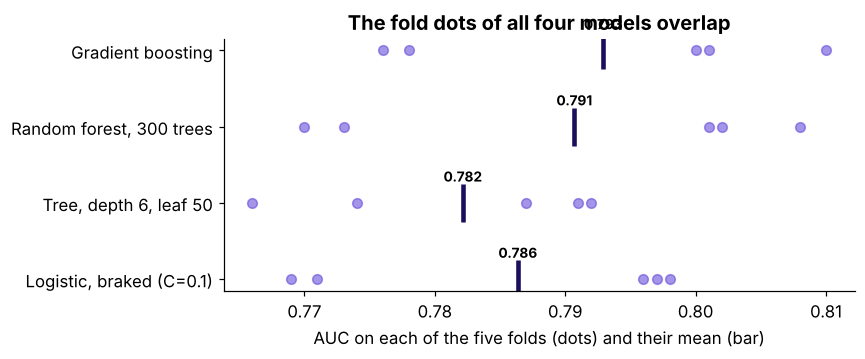

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, r in race.iterrows():
    ax.scatter(r["folds"], [i] * 5, color=VIOLET, alpha=0.55, s=40)
    ax.scatter([r["cv_mean"]], [i], color=INK, marker="|", s=600, lw=3)
    ax.text(r["cv_mean"], i + 0.28, f"{r['cv_mean']:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_yticks(range(len(race))); ax.set_yticklabels(race["model"])
ax.set_xlabel("AUC on each of the five folds (dots) and their mean (bar)")
ax.set_title("The fold dots of all four models overlap")
plt.tight_layout(); plt.show()

**What happened.** (b). **Read the gap fold by fold.** The spread across folds is mostly how hard each fold's customers are,
and every model shares that. The fair test lines the models up on the same fold and subtracts.

In [8]:
lg_folds = np.array(race.loc[0, "folds"]); gb_folds = np.array(race.loc[3, "folds"])
paired = gb_folds - lg_folds
print("boosting minus logistic, fold by fold:", paired.round(3))
print(f"mean lead {paired.mean():.4f} AUC; boosting wins {int((paired > 0).sum())} of 5 folds")
check("boosting's lead is real: it wins every fold against the logistic model", (paired > 0).all())
check("and small: under 0.02 AUC on every fold", (paired < 0.02).all())

boosting minus logistic, fold by fold: [0.007 0.007 0.003 0.014 0.003]
mean lead 0.0068 AUC; boosting wins 5 of 5 folds
PASS  boosting's lead is real: it wins every fold against the logistic model
PASS  and small: under 0.02 AUC on every fold


So the lead is real and small. A real lead and a worthwhile lead are two different tests, and the
second is answered in rupees.

## Step 3: What is the gap worth in rupees? First at Tuesday's cost threshold

A nudge costs Rs 40 and a buyer is worth Rs 1,200 of margin to Kalpa, so Tuesday's rule acts when the
chance of buying beats 40 / 1,240, about 0.032. The bill counts both mistakes: nudges wasted on
non-buyers and buyers missed.

In [9]:
NUDGE, MARGIN = 40, 1200
threshold = NUDGE / (NUDGE + MARGIN)
y = y_val.values
bill = {}
for name, p in scores.items():
    act = p >= threshold
    fp, fn = int((act & (y == 0)).sum()), int((~act & (y == 1)).sum())
    bill[name] = fp * NUDGE + fn * MARGIN
bill["Nudge everyone"] = int((y == 0).sum()) * NUDGE
for k, v in bill.items():
    print(f"{k:28s} Rs {v:,}")

Logistic, braked (C=0.1)     Rs 278,560
Tree, depth 6, leaf 50       Rs 284,200
Random forest, 300 trees     Rs 284,360
Gradient boosting            Rs 281,960
Nudge everyone               Rs 292,400


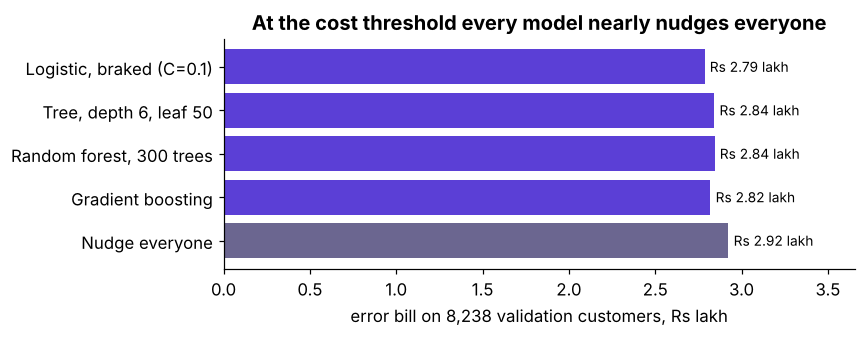

PASS  the four bills sit within 5 percent of each other


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(bill); vals = [bill[n] / 1e5 for n in names]
ax.barh(names, vals, color=[VIOLET] * 4 + [MUTED])
for i, v in enumerate(vals):
    ax.text(v + 0.03, i, f"Rs {v:.2f} lakh", va="center", fontsize=9)
ax.set_xlim(0, max(vals) * 1.25); ax.set_xlabel("error bill on 8,238 validation customers, Rs lakh")
ax.set_title("At the cost threshold every model nearly nudges everyone")
ax.invert_yaxis(); plt.tight_layout(); plt.show()
spread_pct = (max(list(bill.values())[:4]) - min(list(bill.values())[:4])) / min(list(bill.values())[:4])
check("the four bills sit within 5 percent of each other", spread_pct < 0.05)

## Step 4: Under the budget, where the ranking decides

5,000 nudges for 41,188 customers is the top 12.1 percent. On the 8,238 validation customers that is
the top 1,000 by score. Count the buyers each model puts in its top 1,000.

In [11]:
k = round(len(y) * 5000 / 41188)
top = {}
for name, p in scores.items():
    buyers = int(y[np.argsort(-p)[:k]].sum())
    top[name] = buyers
    print(f"{name:28s} {buyers} buyers in the top {k:,}  (precision {buyers / k:.1%}, "
          f"campaign value Rs {buyers * MARGIN - k * NUDGE:,})")
print(f"Base rate: {y.mean():.1%} of customers buy, so a random {k:,} would hold about {y.mean() * k:.0f}")

Logistic, braked (C=0.1)     465 buyers in the top 1,000  (precision 46.5%, campaign value Rs 518,000)
Tree, depth 6, leaf 50       469 buyers in the top 1,000  (precision 46.9%, campaign value Rs 522,800)
Random forest, 300 trees     476 buyers in the top 1,000  (precision 47.6%, campaign value Rs 531,200)
Gradient boosting            472 buyers in the top 1,000  (precision 47.2%, campaign value Rs 526,400)
Base rate: 11.3% of customers buy, so a random 1,000 would hold about 113


## Step 5: Is boosting's lead in the top 12 percent stable? Ask each fold

Inside each training fold, compare the logistic model and boosting on the same held-out customers,
scaled to a 5,000-nudge campaign.

In [12]:
lg = models["Logistic, braked (C=0.1)"]; gb = models["Gradient boosting"]
gaps = []
for a, b in folds.split(X_train, y_train):
    yb = y_train.iloc[b].values
    kk = round(len(b) * 5000 / 41188)
    found = []
    for m in (lg, gb):
        m.fit(X_train.iloc[a], y_train.iloc[a])
        p = m.predict_proba(X_train.iloc[b])[:, 1]
        found.append(yb[np.argsort(-p)[:kk]].sum() * 5000 / kk)
    gaps.append(found[1] - found[0])
gaps = np.array(gaps)
print("extra buyers per 5,000 nudges with boosting, fold by fold:", gaps.round(0))
print(f"mean {gaps.mean():.0f}, spread {gaps.std():.0f}; low end (mean minus spread) {gaps.mean() - gaps.std():.0f}")
print(f"in rupees: mean Rs {gaps.mean() * MARGIN:,.0f}, low end Rs {(gaps.mean() - gaps.std()) * MARGIN:,.0f} a campaign")

extra buyers per 5,000 nudges with boosting, fold by fold: [  0. 133. 100.  92. 125.]
mean 90, spread 48; low end (mean minus spread) 42
in rupees: mean Rs 108,000, low end Rs 50,939 a campaign


## Step 6: The gap at which the complex model ships

Boosting costs more than its licence-free code: a second pipeline to run and monitor, explanations a
committee can check, a longer review when it drifts. Kalpa's platform team has not priced that yet,
so the cell carries an **invented** extra cost per campaign. Change it and watch the call flip.

Boosting ships when it adds more than 62 buyers per 5,000 nudges at the low end
of its fold range. Today's low end is 42 buyers (Rs 50,939).
Provisional call: the braked logistic model


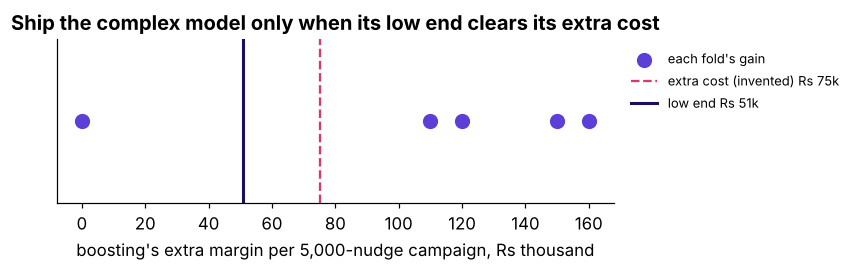

PASS  the call follows the rule: low-end gain against the extra cost
PASS  one fold shows boosting adding nothing or less


In [13]:
EXTRA_COST = 75_000            # invented: extra cost per campaign of running and explaining boosting
low_gain = (gaps.mean() - gaps.std()) * MARGIN
mean_gain = gaps.mean() * MARGIN
break_even = EXTRA_COST / MARGIN
print(f"Boosting ships when it adds more than {break_even:.0f} buyers per 5,000 nudges at the low end")
print(f"of its fold range. Today's low end is {gaps.mean() - gaps.std():.0f} buyers (Rs {low_gain:,.0f}).")
decision = "boosting" if low_gain > EXTRA_COST else "the braked logistic model"
print("Provisional call:", decision)

fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.scatter(gaps * MARGIN / 1000, [0] * len(gaps), s=80, color=VIOLET, zorder=3, label="each fold's gain")
ax.axvline(EXTRA_COST / 1000, color=ROSE, ls="--", label=f"extra cost (invented) Rs {EXTRA_COST / 1000:.0f}k")
ax.axvline(low_gain / 1000, color=INK, lw=2, label=f"low end Rs {low_gain / 1000:.0f}k")
ax.set_yticks([]); ax.set_xlabel("boosting's extra margin per 5,000-nudge campaign, Rs thousand")
ax.legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Ship the complex model only when its low end clears its extra cost")
plt.tight_layout(); plt.show()
check("the call follows the rule: low-end gain against the extra cost",
      (decision == "boosting") == (low_gain > EXTRA_COST))
check("one fold shows boosting adding nothing or less", gaps.min() <= 0.5 * gaps.mean())

## Your provisional recommendation (Friday turns it into the memo)

| Part | Say it with your numbers |
|---|---|
| Claim | Ship the braked logistic model for the first campaign. |
| Evidence | Boosting leads by about 0.007 AUC and wins every fold; at the cost threshold the four bills sit within about 2 percent; under the 5,000-nudge budget boosting's extra buyers swing from 0 to 133 across folds, a low end worth about Rs 51,000 against an extra cost priced (invented) at Rs 75,000. |
| Caveat | The folds mix 2008 to 2010; Friday scores the late months with a model trained on the early ones. |
| Action | Re-race on Friday's time split; switch to boosting when its low-end gain beats its priced extra cost. |

**The flip, in one line.** The complex model ships when its gain at the low end of the fold range is
larger than what it costs to run and explain, or when the decision needs an interaction only it captures.